In [ ]:
import sqlite3
import random
from datetime import datetime

# Connect to SQLite DB
conn = sqlite3.connect("chemicals.db")
cursor = conn.cursor()

# Create Tables
cursor.execute("""
CREATE TABLE IF NOT EXISTS Chemicals (
    chemical_id INTEGER PRIMARY KEY AUTOINCREMENT,
    chemical_name TEXT,
    expiration_date TEXT,
    storage_location TEXT
);
""")

cursor.execute("""
CREATE TABLE IF NOT EXISTS Rooms (
    room_id INTEGER PRIMARY KEY AUTOINCREMENT,
    room_name TEXT
);
""")

cursor.execute("""
CREATE TABLE IF NOT EXISTS Temperature_Readings (
    reading_id INTEGER PRIMARY KEY AUTOINCREMENT,
    chemical_id INTEGER,
    temperature REAL,
    timestamp TEXT,
    room_id INTEGER
);
""")

cursor.execute("""
CREATE TABLE IF NOT EXISTS Chemical_Usage (
    usage_id INTEGER PRIMARY KEY AUTOINCREMENT,
    chemical_id INTEGER,
    user_id INTEGER,
    usage_timestamp TEXT,
    room_id INTEGER
);
""")

conn.commit()

# Insert sample data
cursor.execute("INSERT OR IGNORE INTO Rooms (room_id, room_name) VALUES (1, 'ICU')")
cursor.execute("INSERT OR IGNORE INTO Rooms (room_id, room_name) VALUES (2, 'Pharmacy')")
cursor.execute("INSERT OR IGNORE INTO Rooms (room_id, room_name) VALUES (3, 'Room 101')")

cursor.execute("INSERT OR IGNORE INTO Chemicals (chemical_name, expiration_date, storage_location) VALUES ('Chemical A', '2025-02-01', 'ICU')")
cursor.execute("INSERT OR IGNORE INTO Chemicals (chemical_name, expiration_date, storage_location) VALUES ('Chemical B', '2025-01-15', 'ICU')")
cursor.execute("INSERT OR IGNORE INTO Chemicals (chemical_name, expiration_date, storage_location) VALUES ('Chemical C', '2024-12-30', 'Pharmacy')")

conn.commit()

# Function: Log temperature
def log_temperature(chemical_id, room_id):
    temp = round(random.uniform(2, 10), 2)
    timestamp = datetime.now().isoformat()

    cursor.execute("""
        INSERT INTO Temperature_Readings (chemical_id, temperature, timestamp, room_id)
        VALUES (?, ?, ?, ?)
    """, (chemical_id, temp, timestamp, room_id))

    conn.commit()
    print(f"Logged Temp: Chemical {chemical_id} | Room {room_id} | {temp}°C")


# Function: Check Temperature Safety
def check_temperature_safety():
    cursor.execute("SELECT chemical_id, temperature FROM Temperature_Readings")
    rows = cursor.fetchall()

    print("\nTemperature Safety Check:")
    for chemical_id, temp in rows:
        if temp < 2 or temp > 8:
            print(f"ALERT: Chemical {chemical_id} is out of range ({temp}°C)!")
        else:
            print(f"OK: Chemical {chemical_id} is safe ({temp}°C).")

# FIFO Usage Logic
def use_chemical_FIFO(room_name, user_id):
    cursor.execute("""
        SELECT chemical_id, chemical_name, expiration_date
        FROM Chemicals
        WHERE storage_location = ?
        ORDER BY expiration_date ASC
        LIMIT 1
    """, (room_name,))

    row = cursor.fetchone()

    if row:
        chemical_id, name, exp_date = row
        timestamp = datetime.now().isoformat()

        cursor.execute("""
            INSERT INTO Chemical_Usage (chemical_id, user_id, usage_timestamp, room_id)
            VALUES (?, ?, ?, (SELECT room_id FROM Rooms WHERE room_name = ?))
        """, (chemical_id, user_id, timestamp, room_name))

        conn.commit()
        print(f"FIFO Used: {name} (ID {chemical_id}) in {room_name}")
    else:
        print("No chemicals in this room.")

# Reports
def report_expiring_chemicals():
    print("\nChemicals Near Expiration:")
    cursor.execute("""
        SELECT chemical_name, expiration_date
        FROM Chemicals
        WHERE expiration_date <= '2025-01-30'
    """)
    for row in cursor.fetchall():
        print(row)

def report_temperature_violations():
    print("\nTemperature Violations:")
    cursor.execute("""
        SELECT chemical_id, temperature
        FROM Temperature_Readings
        WHERE temperature < 2 OR temperature > 8
    """)
    for row in cursor.fetchall():
        print(row)

# Run example operations
log_temperature(1, 1)
log_temperature(2, 1)
log_temperature(3, 2)

check_temperature_safety()

use_chemical_FIFO("ICU", user_id=10)

report_expiring_chemicals()
report_temperature_violations()



Logged Temp: Chemical 1 | Room 1 | 2.62°C
Logged Temp: Chemical 2 | Room 1 | 9.53°C
Logged Temp: Chemical 3 | Room 2 | 9.77°C

Temperature Safety Check:
OK: Chemical 1 is safe (6.14°C).
OK: Chemical 2 is safe (5.13°C).
OK: Chemical 3 is safe (3.8°C).
OK: Chemical 1 is safe (5.79°C).
OK: Chemical 2 is safe (7.55°C).
OK: Chemical 3 is safe (5.42°C).
OK: Chemical 1 is safe (3.27°C).
OK: Chemical 2 is safe (3.79°C).
OK: Chemical 3 is safe (3.23°C).
OK: Chemical 1 is safe (2.6°C).
OK: Chemical 2 is safe (6.16°C).
OK: Chemical 3 is safe (7.89°C).
OK: Chemical 1 is safe (3.35°C).
OK: Chemical 2 is safe (3.27°C).
OK: Chemical 3 is safe (6.84°C).
OK: Chemical 1 is safe (5.14°C).
OK: Chemical 2 is safe (4.13°C).
OK: Chemical 3 is safe (6.24°C).
OK: Chemical 1 is safe (6.8°C).
OK: Chemical 2 is safe (2.96°C).
OK: Chemical 3 is safe (2.7°C).
OK: Chemical 1 is safe (5.41°C).
OK: Chemical 2 is safe (6.83°C).
OK: Chemical 3 is safe (5.5°C).
OK: Chemical 1 is safe (4.12°C).
OK: Chemical 2 is safe (5.7

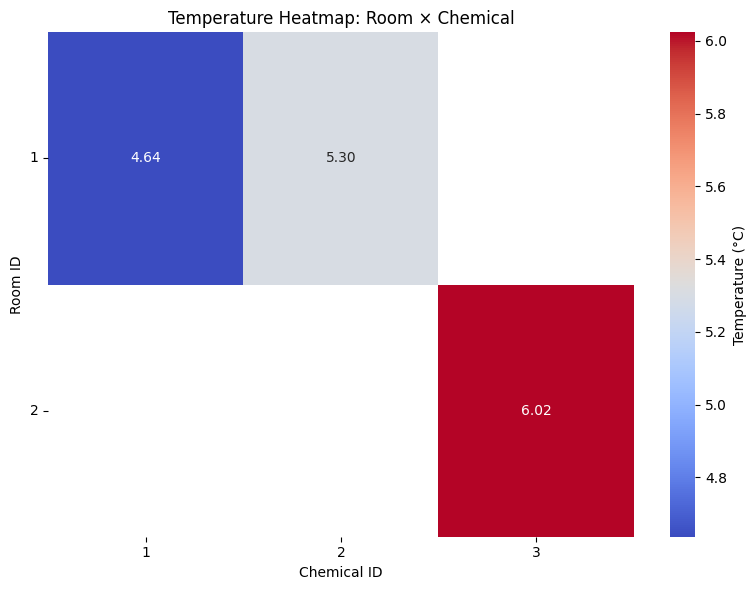

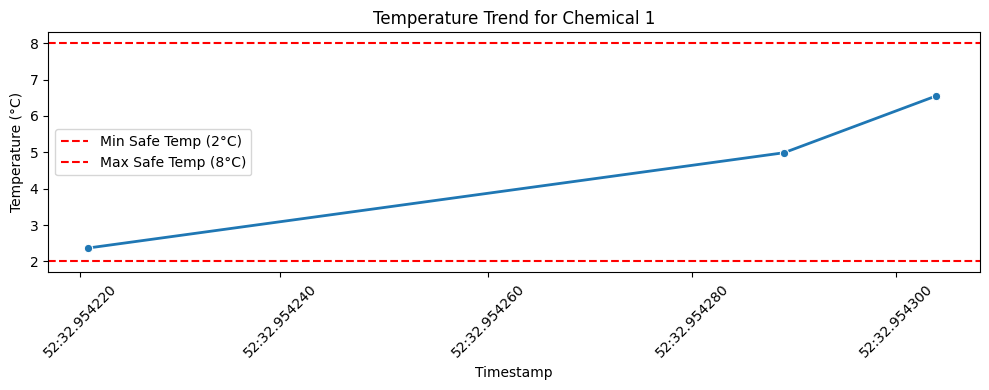

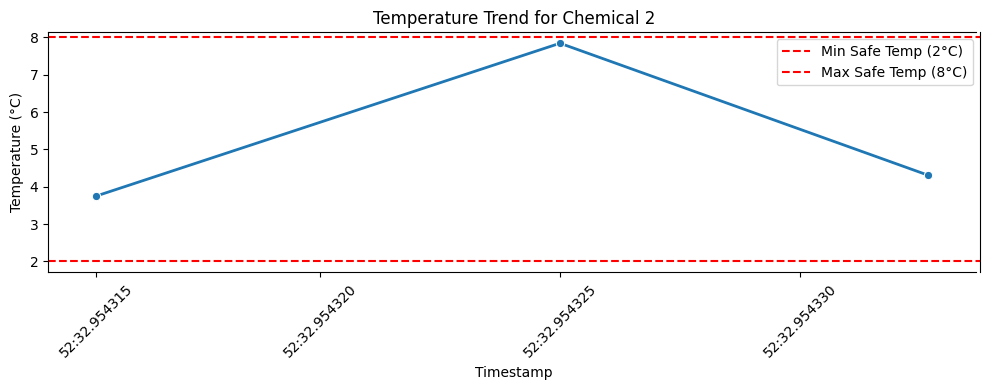

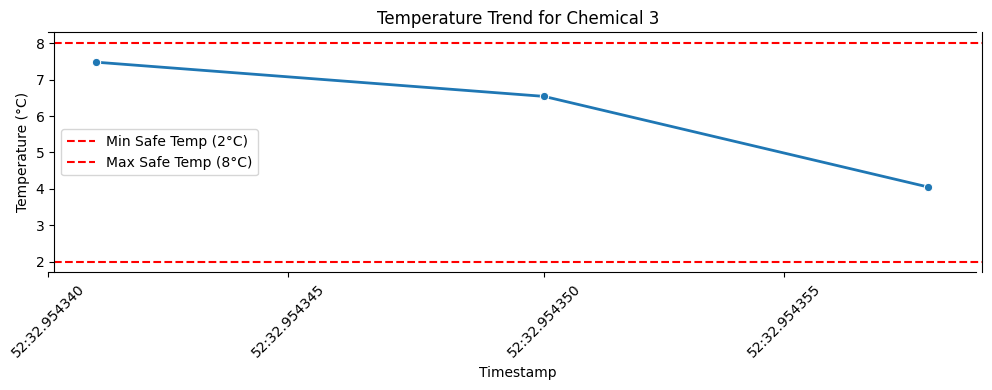

In [ ]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import random

# -----------------------------
# Setup SQLite DB and sample data
# -----------------------------
conn = sqlite3.connect(":memory:")  # in-memory DB for demo
cursor = conn.cursor()

# Create tables
cursor.execute("CREATE TABLE Chemicals (chemical_id INTEGER PRIMARY KEY, chemical_name TEXT, expiration_date TEXT, storage_location TEXT)")
cursor.execute("CREATE TABLE Rooms (room_id INTEGER PRIMARY KEY, room_name TEXT)")
cursor.execute("CREATE TABLE Temperature_Readings (reading_id INTEGER PRIMARY KEY, chemical_id INTEGER, temperature REAL, timestamp TEXT, room_id INTEGER)")

# Insert sample rooms and chemicals
cursor.execute("INSERT INTO Rooms VALUES (1,'ICU'), (2,'Pharmacy')")
cursor.execute("INSERT INTO Chemicals VALUES (1,'Chemical A','2025-02-01','ICU'), (2,'Chemical B','2025-01-15','ICU'), (3,'Chemical C','2024-12-30','Pharmacy')")

# Insert sample temperatures
for chem_id, room_id in [(1,1),(2,1),(3,2)]:
    for i in range(3):  # 3 readings each
        temp = round(random.uniform(2,8),2)
        timestamp = datetime.now().isoformat()
        cursor.execute("INSERT INTO Temperature_Readings (chemical_id, temperature, timestamp, room_id) VALUES (?,?,?,?)",
                       (chem_id, temp, timestamp, room_id))
conn.commit()

# -----------------------------
# Heatmap Visualization
# -----------------------------
def show_temperature_heatmap():
    df = pd.read_sql_query("SELECT room_id, chemical_id, temperature FROM Temperature_Readings", conn)
    if df.empty:
        print("No data for heatmap")
        return

    heatmap_data = df.pivot_table(values="temperature", index="room_id", columns="chemical_id", aggfunc='mean')

    plt.figure(figsize=(8,6))
    sns.heatmap(heatmap_data, annot=True, fmt=".2f", cmap="coolwarm", cbar_kws={'label':'Temperature (°C)'})
    plt.title("Temperature Heatmap: Room × Chemical")
    plt.xlabel("Chemical ID")
    plt.ylabel("Room ID")
    plt.yticks(rotation=0)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()  # <- This will display the plot as output

# -----------------------------
# Temperature Trend Plot
# -----------------------------
def show_temperature_trend(chemical_id):
    df = pd.read_sql_query("SELECT timestamp, temperature FROM Temperature_Readings WHERE chemical_id=? ORDER BY timestamp ASC",
                           conn, params=(chemical_id,))
    if df.empty:
        print(f"No data for Chemical {chemical_id}")
        return

    df['timestamp'] = pd.to_datetime(df['timestamp'])
    plt.figure(figsize=(10,4))
    sns.lineplot(x='timestamp', y='temperature', data=df, marker='o', linewidth=2)
    plt.axhline(2, color='red', linestyle='--', label='Min Safe Temp (2°C)')
    plt.axhline(8, color='red', linestyle='--', label='Max Safe Temp (8°C)')
    plt.title(f"Temperature Trend for Chemical {chemical_id}")
    plt.xlabel("Timestamp")
    plt.ylabel("Temperature (°C)")
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()  # <- This will display the plot as output

# -----------------------------
# Run visualizations
# -----------------------------
show_temperature_heatmap()
show_temperature_trend(1)
show_temperature_trend(2)
show_temperature_trend(3)
